In [1]:
#  Franco De Escondrillas ft. Claude Code · 2026-11-26

# Reparto del verde con Shapley

Cada semáforo del anillo exterior calcula Shapley **en vivo** con sus colas (`TrafficLightAgent.deliberate`). Aquí se comprueba la función y se recorren todas las colas posibles para ver qué decide, sin correr la simulación.

- **Jugadores:** las fases `RING` y `MERGE`.
- **Valor de una coalición:** `v(S) = N·ciclo − τ(N)`, con `τ(n) = d + n·h`.
- **Verde de cada fase:** `CYCLE_TIME · φ_i / Σφ`, con un mínimo de `MIN_GREEN`.

In [2]:
import sys

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "..")   # importa config y agents desde la raíz del repo

from agents.game_theory import coalition_value, green_split, shapley
from agents.traffic_light import MERGE, RING
from config import CYCLE_TIME, MIN_GREEN, SHAPLEY_MAX_QUEUE

## Comprobaciones

Eficiencia (`Σφ = v(N)`) en el ejemplo de clase y, con dos fases, la fórmula cerrada `φ_i = ½·v({i}) + ½·(v(T) − v({j}))`.

In [3]:
class_example = {
    frozenset(): 0.0, frozenset([1]): 10.0, frozenset([2]): 10.0, frozenset([3]): 20.0,
    frozenset([1, 2]): 25.0, frozenset([1, 3]): 35.0, frozenset([2, 3]): 40.0, frozenset([1, 2, 3]): 50.0,
}
phi = shapley([1, 2, 3], class_example.get)
assert abs(sum(phi.values()) - 50.0) < 1e-9
print("ejemplo de clase:", {k: round(x, 3) for k, x in phi.items()}, f"· Σφ = {sum(phi.values()):.1f}")

for n_ring in range(SHAPLEY_MAX_QUEUE + 1):
    for n_merge in range(SHAPLEY_MAX_QUEUE + 1):
        queues = {RING: n_ring, MERGE: n_merge}
        v = lambda s: coalition_value(queues, frozenset(s))
        phi = shapley([RING, MERGE], v)
        assert abs(phi[RING] - (0.5 * v({RING}) + 0.5 * (v({RING, MERGE}) - v({MERGE})))) < 1e-9
        assert abs(sum(phi.values()) - v({RING, MERGE})) < 1e-9
print("dos fases: coincide con la fórmula cerrada y Σφ = v(T)")

ejemplo de clase: {1: 11.667, 2: 14.167, 3: 24.167} · Σφ = 50.0
dos fases: coincide con la fórmula cerrada y Σφ = v(T)


## Verde según las colas

verde de MERGE (s) en un ciclo de 40 s
anillo \ radio      0     1     2     3     4     5     6     7     8
             0    6.0  40.0  40.0  40.0  40.0  40.0  40.0  40.0  40.0
             1    6.0  20.0  26.8  30.1  32.1  33.5  34.4  35.1  35.6
             2    6.0  13.2  20.0  24.0  26.7  28.6  30.1  31.2  32.1
             3    6.0   9.9  16.0  20.0  22.9  25.0  26.7  28.0  29.1
             4    6.0   7.9  13.3  17.1  20.0  22.2  24.0  25.5  26.7
             5    6.0   6.5  11.4  15.0  17.8  20.0  21.8  23.3  24.6
             6    6.0   6.0   9.9  13.3  16.0  18.2  20.0  21.5  22.9
             7    6.0   6.0   8.8  12.0  14.5  16.7  18.5  20.0  21.3
             8    6.0   6.0   7.9  10.9  13.3  15.4  17.1  18.7  20.0


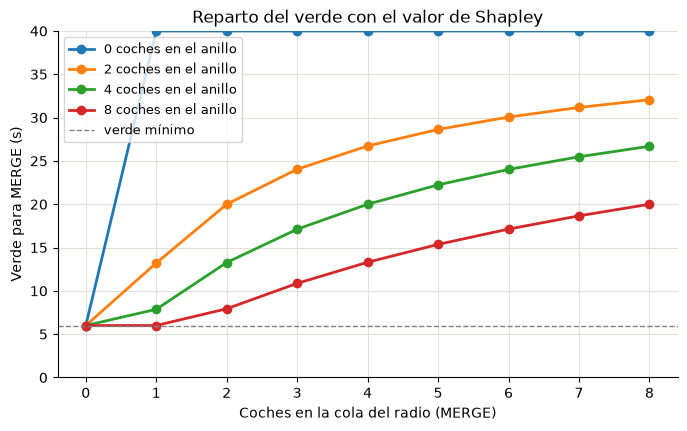

In [4]:
def merge_green(n_ring: int, n_merge: int) -> float:
    """Verde (s) que presupuesta el semáforo para MERGE, como en `TrafficLightAgent.deliberate`."""
    _, share = green_split({RING: n_ring, MERGE: n_merge}, default=RING)
    return max(MIN_GREEN, CYCLE_TIME * share[MERGE])


queues = range(SHAPLEY_MAX_QUEUE + 1)
print(f"verde de MERGE (s) en un ciclo de {CYCLE_TIME:.0f} s")
print("anillo \\ radio " + "".join(f"{n:6d}" for n in queues))
for n_ring in queues:
    print(f"{n_ring:14d} " + "".join(f"{merge_green(n_ring, n_merge):6.1f}" for n_merge in queues))

fig, ax = plt.subplots(figsize=(8, 4.5))
for n_ring in (0, 2, 4, 8):
    ax.plot(queues, [merge_green(n_ring, m) for m in queues], marker="o", lw=2, label=f"{n_ring} coches en el anillo")
ax.axhline(MIN_GREEN, color="0.5", ls="--", lw=1, label="verde mínimo")
ax.set_xlabel("Coches en la cola del radio (MERGE)")
ax.set_ylabel("Verde para MERGE (s)")
ax.set_title("Reparto del verde con el valor de Shapley")
ax.set_ylim(0, CYCLE_TIME)
ax.grid(color="#e1e0d9", lw=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(fontsize=9)
plt.show()